In [ ]:
import torch
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam, Saliency, DeepLift, GuidedBackprop, InputXGradient
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM, \
    ScoreCAM, \
    GradCAMPlusPlus, \
    AblationCAM, \
    XGradCAM, \
    EigenCAM, \
    EigenGradCAM, \
    LayerCAM, \
    FullGrad, \
    GradCAMElementWise
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    preprocess_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings
from medcam import medcam

import os
import torch.backends.cudnn as cudnn
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import imageio

In [ ]:
import nibabel as nib

In [25]:
zz = nib.load('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction/val/interpretability/special_medcam/features.5.2.conv2/attention_map_0_0_0.nii.gz').get_fdata()

In [26]:
zz.shape

(32, 38, 32)

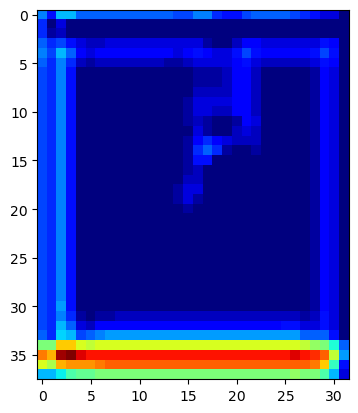

In [24]:
plt.imshow(zz[28,:,:], cmap='jet')

In [ ]:
# load model name
xy = torch.load('/gpfs/data/mayerhoeferlab/projects/myeloma/results/train_3d/train_all_seeds_11-16-25/checkpoint_seed0_run0_best.pth')

/tmp/ipykernel_4094045/3663976880.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  xy = torch.load('/gpfs/data/mayerhoeferlab/projects/myeloma/results/train_3d/train_all_

In [ ]:
model.load_state_dict(xy['state_dict'])

odict_keys(['features.0.weight', 'features.1.weight', 'features.1.bias', 'features.1.running_mean', 'features.1.running_var', 'features.1.num_batches_tracked', 'features.4.0.conv1.weight', 'features.4.0.bn1.weight', 'features.4.0.bn1.bias', 'features.4.0.bn1.running_mean', 'features.4.0.bn1.running_var', 'features.4.0.bn1.num_batches_tracked', 'features.4.0.conv2.weight', 'features.4.0.bn2.weight', 'features.4.0.bn2.bias', 'features.4.0.bn2.running_mean', 'features.4.0.bn2.running_var', 'features.4.0.bn2.num_batches_tracked', 'features.4.1.conv1.weight', 'features.4.1.bn1.weight', 'features.4.1.bn1.bias', 'features.4.1.bn1.running_mean', 'features.4.1.bn1.running_var', 'features.4.1.bn1.num_batches_tracked', 'features.4.1.conv2.weight', 'features.4.1.bn2.weight', 'features.4.1.bn2.bias', 'features.4.1.bn2.running_mean', 'features.4.1.bn2.running_var', 'features.4.1.bn2.num_batches_tracked', 'features.4.2.conv1.weight', 'features.4.2.bn1.weight', 'features.4.2.bn1.bias', 'features.4.2.b